# 09 · Kompilasi Hasil: Tabel Metrik (Bagian IV) & Figur (Bagian V)

Notebook ini **tidak melatih apa pun**. Notebook ini hanya mengumpulkan hasil yang sudah disimpan oleh notebook 01–08 di folder `results/`, lalu membuat:
- **Tabel komparasi metrik** pada Test Set (Bagian IV laporan),
- **Tabel konfigurasi parameter** (Bagian II laporan),
- **Figur 1, 2, 4, 5** (Figur 3 sudah dibuat di notebook 08),
- **Figur pendukung S1–S4** untuk memperkuat jawaban Q1–Q6.

Tabel disimpan di `results/tables/` dan figur di `results/figures/` dalam format PNG 300 dpi dan PDF.

In [1]:
%run ./00_helpers.ipynb

device = cuda | dataset = fashion_mnist | QUICK = False
folder proyek = c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN
hasil -> c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results
Helpers siap ✔


c:\Users\Derry\Anaconda\envs\deep-learning\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Kumpulkan Hasil Semua Model

In [2]:
MODELS = ["vanilla_ae", "sparse_ae", "vae", "gan", "dcgan", "ddpm"]
DISPLAY = {"vanilla_ae": "Vanilla Autoencoder", "sparse_ae": "Sparse Autoencoder",
           "vae": "Variational Autoencoder (VAE)", "gan": "Vanilla GAN (MLP)", "dcgan": "DCGAN", "ddpm": "DDPM"}

M, A, H = {}, {}, {}
for n in MODELS:
    if (RESULTS_DIR / "metrics" / f"{n}.json").exists():
        M[n] = load_json(RESULTS_DIR / "metrics" / f"{n}.json")
        A[n] = torch.load(RESULTS_DIR / "artifacts" / f"{n}.pt", weights_only=False)
        H[n] = load_json(RESULTS_DIR / "histories" / f"{n}.json")
    else:
        print(f"[BELUM ADA] {n} -> jalankan notebook model ini dulu")
print("Model yang sudah ada hasilnya:", list(M))

Model yang sudah ada hasilnya: ['vanilla_ae', 'sparse_ae', 'vae', 'gan', 'dcgan', 'ddpm']


## 2. Tabel Komparasi Metrik (Bagian IV)

Format mengikuti template panduan, ditambah kolom **SSIM**, **Params**, dan **latency per 1 sampel** (untuk Q6).

In [3]:
LATENT = {"vanilla_ae": "64", "sparse_ae": "64 (Bottleneck) / 256 (Sparse)", "vae": "64",
          "gan": "100 (Prior Noise)", "dcgan": "100 (Prior Noise)", "ddpm": "1x28x28 (Dimensi Citra)"}
NA_FID = {"vanilla_ae": "N/A (Latent Voids)", "sparse_ae": "N/A (Latent Voids)"}
NA_REC = {"gan": "N/A (Tanpa Encoder)", "dcgan": "N/A (Tanpa Encoder)", "ddpm": "N/A (Denoising Model)"}

def fmt(v, nd):
    return "N/A" if v is None else f"{v:.{nd}f}"

header = ["Arsitektur Model", "Dim Laten", "Params", "Training Time / Epoch (s)", "Latency (ms / batch 64)",
          "Latency (ms / 1 sampel)", "Test MSE", "Test PSNR (dB)", "Test SSIM", "FID Score", "Kestabilan Training"]
table = []
for n, m in M.items():
    table.append([DISPLAY[n], LATENT[n], f"{m['params']:,}", fmt(m["train_time_per_epoch_s"], 2),
                  fmt(m["latency_ms_batch64"], 2), fmt(m["latency_ms_batch1"], 2),
                  fmt(m["mse"], 5) if "mse" in m else NA_REC.get(n, "N/A"),
                  fmt(m["psnr"], 2) if "psnr" in m else "N/A",
                  fmt(m["ssim"], 4) if "ssim" in m else "N/A",
                  fmt(m.get("fid"), 2) if n not in NA_FID else NA_FID[n],
                  m["stability"]["label"]])

with open(TABLES_DIR / "metrics_table.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f); w.writerow(header); w.writerows(table)
with open(TABLES_DIR / "metrics_table.md", "w", encoding="utf-8") as f:
    f.write("| " + " | ".join(header) + " |\n|" + "---|" * len(header) + "\n")
    for r in table:
        f.write("| " + " | ".join(r) + " |\n")

from IPython.display import Markdown, display
display(Markdown(open(TABLES_DIR / "metrics_table.md", encoding="utf-8").read()))
print("Catatan: label kestabilan bersifat heuristik. Cek juga Figur 5 dan Figur S2.")

| Arsitektur Model | Dim Laten | Params | Training Time / Epoch (s) | Latency (ms / batch 64) | Latency (ms / 1 sampel) | Test MSE | Test PSNR (dB) | Test SSIM | FID Score | Kestabilan Training |
|---|---|---|---|---|---|---|---|---|---|---|
| Vanilla Autoencoder | 64 | 435,536 | 1.50 | 0.35 | 0.35 | 0.00819 | 21.93 | 0.7417 | N/A (Latent Voids) | Stabil / Konvergen |
| Sparse Autoencoder | 64 (Bottleneck) / 256 (Sparse) | 435,536 | 1.23 | 0.30 | 0.30 | 0.00872 | 21.63 | 0.7337 | N/A (Latent Voids) | Stabil / Konvergen |
| Variational Autoencoder (VAE) | 64 | 451,984 | 1.52 | 0.18 | 0.16 | 0.01324 | 19.63 | 0.6465 | 87.86 | Stabil / Konvergen |
| Vanilla GAN (MLP) | 100 (Prior Noise) | 2,019,857 | 3.56 | 0.41 | 0.32 | N/A (Tanpa Encoder) | N/A | N/A | 106.81 | Cukup stabil |
| DCGAN | 100 (Prior Noise) | 1,920,194 | 6.63 | 1.82 | 0.50 | N/A (Tanpa Encoder) | N/A | N/A | 21.43 | Cukup stabil |
| DDPM | 1x28x28 (Dimensi Citra) | 4,659,777 | 73.91 | 21023.18 | 14283.75 | N/A (Denoising Model) | N/A | N/A | 9.54 | Stabil / Konvergen |


Catatan: label kestabilan bersifat heuristik. Cek juga Figur 5 dan Figur S2.


## 3. Ringkasan Angka Pendukung (Q1–Q6)

In [4]:
rows = []
for n in ["vae", "gan", "dcgan", "ddpm"]:
    mc = M.get(n, {}).get("mode_coverage")
    if mc:
        rows.append(f"| {SHORT[n]} | {mc['entropy_norm']:.3f} | {mc['modes_covered']} / 10 |")
txt = "**Mode coverage** (entropi 1.0 = semua kelas merata)\n\n| Model | Entropi | Kelas tercakup |\n|---|---|---|\n" + "\n".join(rows)

rows = []
for n in ["vanilla_ae", "sparse_ae"]:
    if n in M:
        s, a = M[n]["sparsity"], M[n]["anomaly"]
        rows.append(f"| {SHORT[n]} | {s['active_frac_mean']:.1%} | {s['dead_units']} | {a['auroc']:.4f} | {a['err_ratio']:.2f} |")
if "vae" in M:
    a = M["vae"]["anomaly"]
    rows.append(f"| VAE (referensi) | – | – | {a['auroc']:.4f} | {a['err_ratio']:.2f} |")
txt += ("\n\n**Sparsity & deteksi anomali**\n\n| Model | Neuron aktif / gambar | Neuron mati | AUROC cacat | Rasio error cacat/normal |\n"
        "|---|---|---|---|---|\n" + "\n".join(rows))

rows = []
for n in ["vanilla_ae", "sparse_ae"]:
    g = M.get(n, {}).get("gaussian_fit_sampling")
    if g:
        rows.append(f"| {SHORT[n]} | {fmt(g.get('fid'), 2)} | {fmt(g['mode_coverage']['entropy_norm'], 3) if g.get('mode_coverage') else 'N/A'} |")
if rows:
    txt += ("\n\n**Sampling acak di ruang laten AE** (alasan FID ditulis N/A (Latent Voids))\n\n| Model | FID | Entropi kelas |\n|---|---|---|\n"
            + "\n".join(rows))
sweep = M.get("sparse_ae", {}).get("lambda_sweep")
if sweep:
    txt += ("\n\n**Pengaruh lambda pada Sparse AE** (training singkat, untuk Q1)\n\n| lambda | Test MSE | Test SSIM | Neuron aktif / gambar |\n|---|---|---|---|\n"
            + "\n".join(f"| {r['lambda']:g} | {r['mse']:.5f} | {r['ssim']:.4f} | {r['active_frac_mean']:.1%} |" for r in sweep))
display(Markdown(txt))
with open(TABLES_DIR / "supporting_metrics.md", "w", encoding="utf-8") as f:
    f.write(txt)

**Mode coverage** (entropi 1.0 = semua kelas merata)

| Model | Entropi | Kelas tercakup |
|---|---|---|
| VAE | 0.985 | 10 / 10 |
| Vanilla GAN | 0.995 | 10 / 10 |
| DCGAN | 0.996 | 10 / 10 |
| DDPM | 0.994 | 10 / 10 |

**Sparsity & deteksi anomali**

| Model | Neuron aktif / gambar | Neuron mati | AUROC cacat | Rasio error cacat/normal |
|---|---|---|---|---|
| Vanilla AE | 52.7% | 86 | 0.7287 | 1.60 |
| Sparse AE | 19.1% | 150 | 0.7244 | 1.57 |
| VAE (referensi) | – | – | 0.6984 | 1.44 |

**Sampling acak di ruang laten AE** (alasan FID ditulis N/A (Latent Voids))

| Model | FID | Entropi kelas |
|---|---|---|
| Vanilla AE | 165.29 | 0.942 |
| Sparse AE | 173.02 | 0.924 |

**Pengaruh lambda pada Sparse AE** (training singkat, untuk Q1)

| lambda | Test MSE | Test SSIM | Neuron aktif / gambar |
|---|---|---|---|
| 0 | 0.01271 | 0.6553 | 52.1% |
| 1e-05 | 0.01247 | 0.6576 | 24.8% |
| 3e-05 | 0.01321 | 0.6404 | 14.2% |
| 0.0001 | 0.01793 | 0.5704 | 3.8% |
| 0.001 | 0.03006 | 0.4269 | 1.2% |

## 4. Tabel Konfigurasi Parameter (Bagian II)
Nilai epoch, learning rate, lambda, beta, dan T dibaca dari hasil yang **benar-benar dijalankan** di setiap notebook.

In [5]:
def hp(n, key, default="?"):
    src = M.get(n) if n in M else (load_json(RESULTS_DIR / "metrics" / f"{n}.json")
                                   if (RESULTS_DIR / "metrics" / f"{n}.json").exists() else {})
    return src.get("hparams", {}).get(key, default)

lam = hp("sparse_ae", "sparse_lambda")
T_used = hp("ddpm", "T")
cfg_rows = [
    ["Vanilla AE", "784-256-64 / 64-256-784", "64", "ReLU, Sigmoid (output)", "MSE",
     "Adam", f"{hp('vanilla_ae', 'lr')}", f"{hp('vanilla_ae', 'epochs')}"],
    ["Sparse AE", "784-256-64 / 64-256-784", "64 (bottleneck) / 256 (sparse)", "ReLU, Sigmoid (output)",
     f"MSE + lambda*||h||_1 (lambda = {lam})", "Adam", f"{hp('sparse_ae', 'lr')}", f"{hp('sparse_ae', 'epochs')}"],
    ["VAE", "784-256-(mu, logvar 64) / 64-256-784", "64", "ReLU, Sigmoid (output)",
     f"BCE + beta*KL (beta = {hp('vae', 'beta')})", "Adam", f"{hp('vae', 'lr')}", f"{hp('vae', 'epochs')}"],
    ["Vanilla GAN", "G: 100-256-512-1024-784 / D: 784-512-256-1", "100", "LeakyReLU(0.2), Tanh (G output)",
     "BCE adversarial (non-saturating)", "Adam (b1 = 0.5, b2 = 0.999)", f"{hp('gan', 'lr')}", f"{hp('gan', 'epochs')}"],
    ["DCGAN", "G: ConvT 100->256x7x7->128x14x14->1x28x28 / D: Conv 1->64->128->1", "100",
     "ReLU+BN (G), LeakyReLU(0.2)+BN (D), Tanh", "BCE adversarial (non-saturating)",
     "Adam (b1 = 0.5, b2 = 0.999)", f"{hp('dcgan', 'lr')}", f"{hp('dcgan', 'epochs')}"],
    ["DDPM", f"U-Net 28->14->7 (ch 64/128/128), ResBlock+GroupNorm, attention 7x7, T = {T_used}", "1x28x28",
     "SiLU", "MSE prediksi noise (L_simple)", f"Adam + EMA {hp('ddpm', 'ema')}", f"{hp('ddpm', 'lr')}",
     f"{hp('ddpm', 'epochs')}"],
    ["MLP Classifier", "784-256-64-10", "64 (z_MLP)", "ReLU, Softmax", "Cross-Entropy", "Adam",
     f"{hp('mlp_classifier', 'lr')}", f"{hp('mlp_classifier', 'epochs')} (early stopping, target test acc >= 88%)"],
]
hdr = ["Model", "Lapisan Arsitektur", "Dim Laten", "Aktivasi", "Loss", "Optimizer", "Learning Rate", "Epoch"]
md = "| " + " | ".join(hdr) + " |\n|" + "---|" * len(hdr) + "\n" + "\n".join("| " + " | ".join(r) + " |" for r in cfg_rows)
md += f"\n\nBatch size {BATCH_SIZE}, seed {SEED}, split 80/10/10 ({DATASET})."
with open(TABLES_DIR / "config_table.md", "w", encoding="utf-8") as f:
    f.write(md)
display(Markdown(md))

| Model | Lapisan Arsitektur | Dim Laten | Aktivasi | Loss | Optimizer | Learning Rate | Epoch |
|---|---|---|---|---|---|---|---|
| Vanilla AE | 784-256-64 / 64-256-784 | 64 | ReLU, Sigmoid (output) | MSE | Adam | 0.001 | 30 |
| Sparse AE | 784-256-64 / 64-256-784 | 64 (bottleneck) / 256 (sparse) | ReLU, Sigmoid (output) | MSE + lambda*||h||_1 (lambda = 3e-05) | Adam | 0.001 | 30 |
| VAE | 784-256-(mu, logvar 64) / 64-256-784 | 64 | ReLU, Sigmoid (output) | BCE + beta*KL (beta = 1.0) | Adam | 0.001 | 30 |
| Vanilla GAN | G: 100-256-512-1024-784 / D: 784-512-256-1 | 100 | LeakyReLU(0.2), Tanh (G output) | BCE adversarial (non-saturating) | Adam (b1 = 0.5, b2 = 0.999) | 0.0002 | 100 |
| DCGAN | G: ConvT 100->256x7x7->128x14x14->1x28x28 / D: Conv 1->64->128->1 | 100 | ReLU+BN (G), LeakyReLU(0.2)+BN (D), Tanh | BCE adversarial (non-saturating) | Adam (b1 = 0.5, b2 = 0.999) | 0.0002 | 30 |
| DDPM | U-Net 28->14->7 (ch 64/128/128), ResBlock+GroupNorm, attention 7x7, T = 1000 | 1x28x28 | SiLU | MSE prediksi noise (L_simple) | Adam + EMA 0.999 | 0.0002 | 40 |
| MLP Classifier | 784-256-64-10 | 64 (z_MLP) | ReLU, Softmax | Cross-Entropy | Adam | 0.001 | 23 (early stopping, target test acc >= 88%) |

Batch size 128, seed 42, split 80/10/10 (fashion_mnist).

## 5. Figur 1: Grid Rekonstruksi Side-by-Side
Baris 1: Ground Truth · Baris 2: Vanilla AE · Baris 3: Sparse AE · Baris 4: VAE

Figur tersimpan: c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results\figures\figure1_reconstruction_grid.png


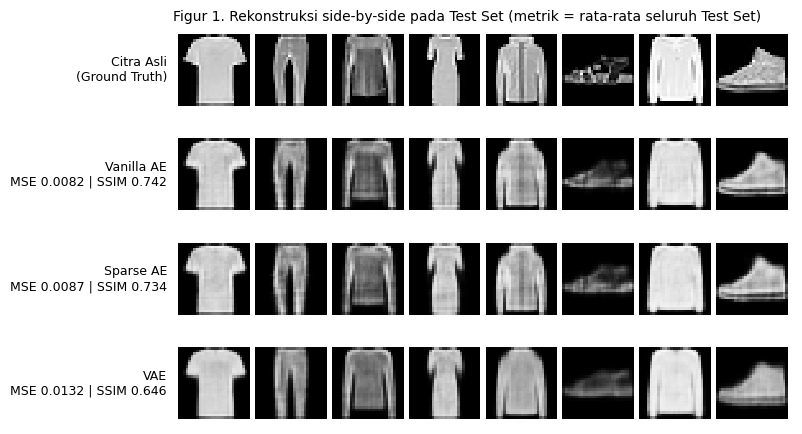

In [6]:
rows = []
any_ae = next((n for n in ["vanilla_ae", "sparse_ae", "vae"] if n in A), None)
if any_ae:
    rows.append(("Citra Asli\n(Ground Truth)", A[any_ae]["x_fixed"]))
for n in ["vanilla_ae", "sparse_ae", "vae"]:
    if n in A:
        rows.append((f"{SHORT[n]}\nMSE {M[n]['mse']:.4f} | SSIM {M[n]['ssim']:.3f}", A[n]["recon_fixed"]))
fig, axes = plt.subplots(len(rows), 1, figsize=(8, 1.3 * len(rows)))
for ax, (lab, imgs) in zip(np.atleast_1d(axes), rows):
    show_imgs(ax, imgs, label=lab)
np.atleast_1d(axes)[0].set_title("Figur 1. Rekonstruksi side-by-side pada Test Set (metrik = rata-rata seluruh Test Set)", loc="left")
save_fig(fig, "figure1_reconstruction_grid"); plt.show()

## 6. Figur 2: Grid Random Generative Sampling (4×4)

Figur tersimpan: c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results\figures\figure2_random_sampling_grid.png


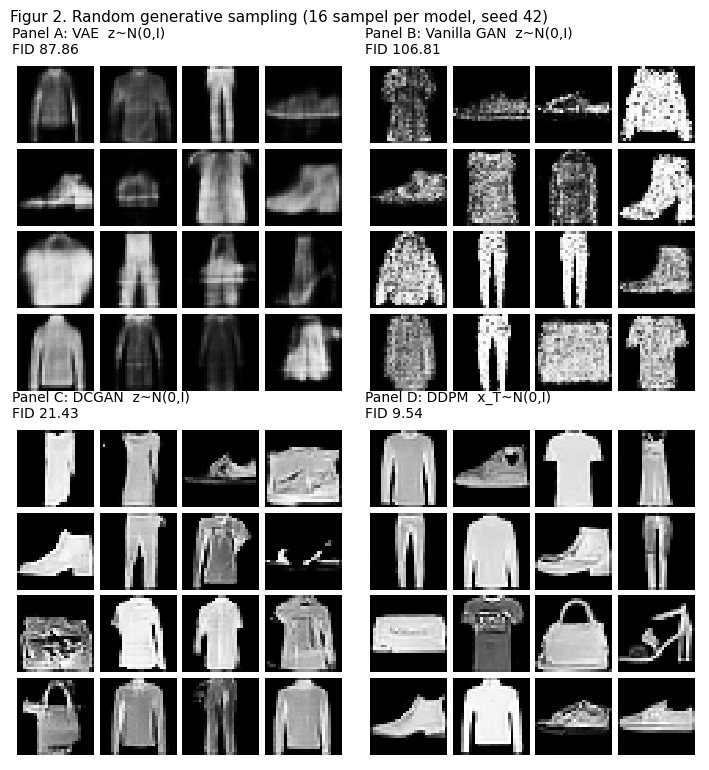

In [7]:
panels = [("A", "vae", "VAE  z~N(0,I)"), ("B", "gan", "Vanilla GAN  z~N(0,I)"),
          ("C", "dcgan", "DCGAN  z~N(0,I)"), ("D", "ddpm", "DDPM  x_T~N(0,I)")]
fig, axes = plt.subplots(2, 2, figsize=(7.2, 7.8))
for ax, (p, n, t) in zip(axes.flat, panels):
    if n not in A:
        ax.axis("off"); ax.set_title(f"Panel {p}: {t} (belum ada)", loc="left"); continue
    fid = M[n].get("fid")
    show_imgs(ax, A[n]["samples16"], nrow=4, title=f"Panel {p}: {t}" + (f"\nFID {fid:.2f}" if fid is not None else ""))
fig.suptitle("Figur 2. Random generative sampling (16 sampel per model, seed 42)", x=0.02, ha="left", fontsize=11)
fig.tight_layout()
save_fig(fig, "figure2_random_sampling_grid"); plt.show()

## 7. Figur 4: Linear Latent Space Interpolation
z(α) = (1 − α) z_A + α z_B, dengan α ∈ {0.0, 0.2, 0.4, 0.6, 0.8, 1.0}

Figur tersimpan: c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results\figures\figure4_latent_interpolation.png


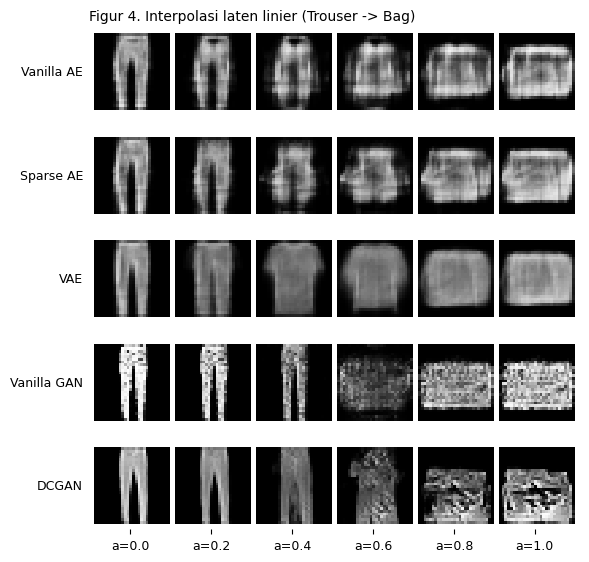

In [8]:
order = [n for n in ["vanilla_ae", "sparse_ae", "vae", "gan", "dcgan"] if n in A]
fig, axes = plt.subplots(len(order), 1, figsize=(6.5, 1.3 * len(order)))
axes = np.atleast_1d(axes)
for ax, n in zip(axes, order):
    show_imgs(ax, A[n]["interp_imgs"], label=SHORT[n])
w = 30
axes[-1].set_xticks([w * i + w / 2 for i in range(len(ALPHAS))])
axes[-1].set_xticklabels([f"a={a:.1f}" for a in ALPHAS])
a, b = INTERP_CLASSES
axes[0].set_title(f"Figur 4. Interpolasi laten linier ({CLASS_NAMES[a]} -> {CLASS_NAMES[b]})", loc="left")
save_fig(fig, "figure4_latent_interpolation"); plt.show()

recs = [r for n in order for r in A[n]["interp_rows"]]
with open(TABLES_DIR / "interpolation_metrics.csv", "w", newline="") as f:
    wr = csv.DictWriter(f, fieldnames=list(recs[0].keys())); wr.writeheader(); wr.writerows(recs)

## 8. Figur 5: Training Loss Curves + DDPM Denoising Trajectory

Figur tersimpan: c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results\figures\figure5_training_curves_ddpm_trajectory.png


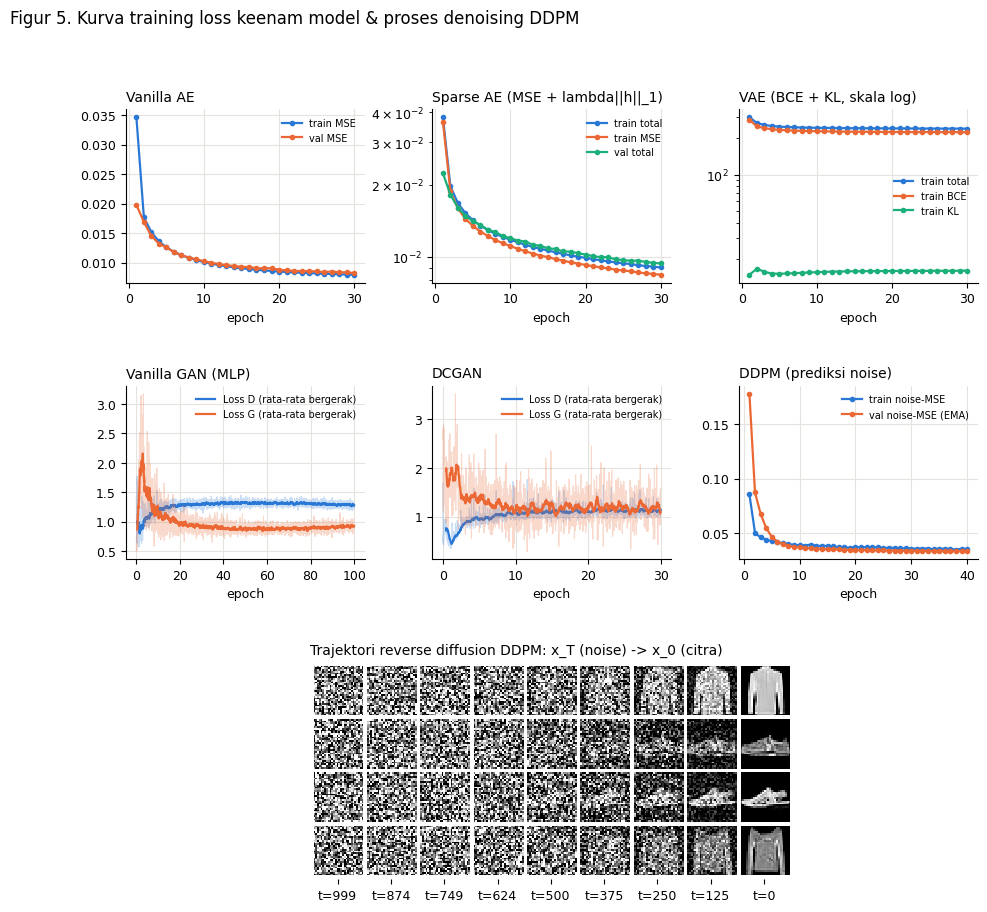

In [9]:
from matplotlib.gridspec import GridSpec

def moving_avg(v, k=20):
    v = np.asarray(v, float)
    return v if len(v) < k else np.convolve(v, np.ones(k) / k, mode="valid")

fig = plt.figure(figsize=(11, 10))
gs = GridSpec(3, 3, figure=fig, height_ratios=[1, 1, 1.25], hspace=0.55, wspace=0.28)
c3 = ["#2a78d6", "#eb6834", "#1baf7a"]

def ep_plot(ax, n, keys, title, log=False):
    if n not in H:
        ax.set_title(f"{title} (belum ada)", loc="left"); return
    for (split, key, lab), col in zip(keys, c3):
        ax.plot(H[n]["epoch"], [e[key] for e in H[n][split]], "-o", ms=3, color=col, label=lab)
    ax.set_title(title, loc="left"); ax.set_xlabel("epoch"); ax.legend(fontsize=7)
    if log:
        ax.set_yscale("log")

def gan_plot(ax, n, title):
    if n not in H:
        ax.set_title(f"{title} (belum ada)", loc="left"); return
    h = H[n]; per_ep = len(h["iter_d_loss"]) / len(h["epoch"])
    for key, col, lab in [("iter_d_loss", c3[0], "Loss D"), ("iter_g_loss", c3[1], "Loss G")]:
        v = np.asarray(h[key]); xs = np.arange(len(v)) / per_ep
        ax.plot(xs, v, color=col, alpha=0.25, lw=0.8)
        m = moving_avg(v); ax.plot(xs[len(xs) - len(m):], m, color=col, label=lab + " (rata-rata bergerak)")
    ax.set_title(title, loc="left"); ax.set_xlabel("epoch"); ax.legend(fontsize=7)

ep_plot(fig.add_subplot(gs[0, 0]), "vanilla_ae", [("train", "loss", "train MSE"), ("val", "loss", "val MSE")], "Vanilla AE")
ep_plot(fig.add_subplot(gs[0, 1]), "sparse_ae", [("train", "loss", "train total"), ("train", "mse", "train MSE"),
                                                ("val", "loss", "val total")], "Sparse AE (MSE + lambda||h||_1)", log=True)
ep_plot(fig.add_subplot(gs[0, 2]), "vae", [("train", "loss", "train total"), ("train", "bce", "train BCE"),
                                          ("train", "kl", "train KL")], "VAE (BCE + KL, skala log)", log=True)
gan_plot(fig.add_subplot(gs[1, 0]), "gan", "Vanilla GAN (MLP)")
gan_plot(fig.add_subplot(gs[1, 1]), "dcgan", "DCGAN")
ep_plot(fig.add_subplot(gs[1, 2]), "ddpm", [("train", "loss", "train noise-MSE"), ("val", "loss", "val noise-MSE (EMA)")],
        "DDPM (prediksi noise)")

ax = fig.add_subplot(gs[2, :])
if "ddpm" in A:
    steps = A["ddpm"]["traj_steps"]
    show_imgs(ax, A["ddpm"]["traj_grid"], nrow=len(steps), title="Trajektori reverse diffusion DDPM: x_T (noise) -> x_0 (citra)")
    ax.set_xticks([30 * i + 15 for i in range(len(steps))]); ax.set_xticklabels([f"t={s}" for s in steps])
else:
    ax.axis("off")
fig.suptitle("Figur 5. Kurva training loss keenam model & proses denoising DDPM", x=0.02, ha="left", fontsize=12)
save_fig(fig, "figure5_training_curves_ddpm_trajectory"); plt.show()

## 9. Figur Pendukung

- **S1** (Q2): filter W1 & tingkat aktivasi hidden layer, Vanilla AE vs Sparse AE
- **S2** (Q3): D(x), D(G(z)), dan norma gradien saturating vs non-saturating, Vanilla GAN vs DCGAN
- **S3** (Q4): jarak ke data latih (*latent voids*) & keyakinan classifier sepanjang interpolasi
- **S4** (Q1, Q3): sebaran kelas sampel sintetis (*mode coverage*)

Jumlah data: {'train': 56000, 'val': 7000, 'test': 7000}


C:\Users\Derry\AppData\Local\Temp\ipykernel_17692\2360388446.py:9: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(ae_ck[n], map_location="cpu")["model"]


Figur tersimpan: c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results\figures\figureS1_sparse_vs_vanilla_features.png


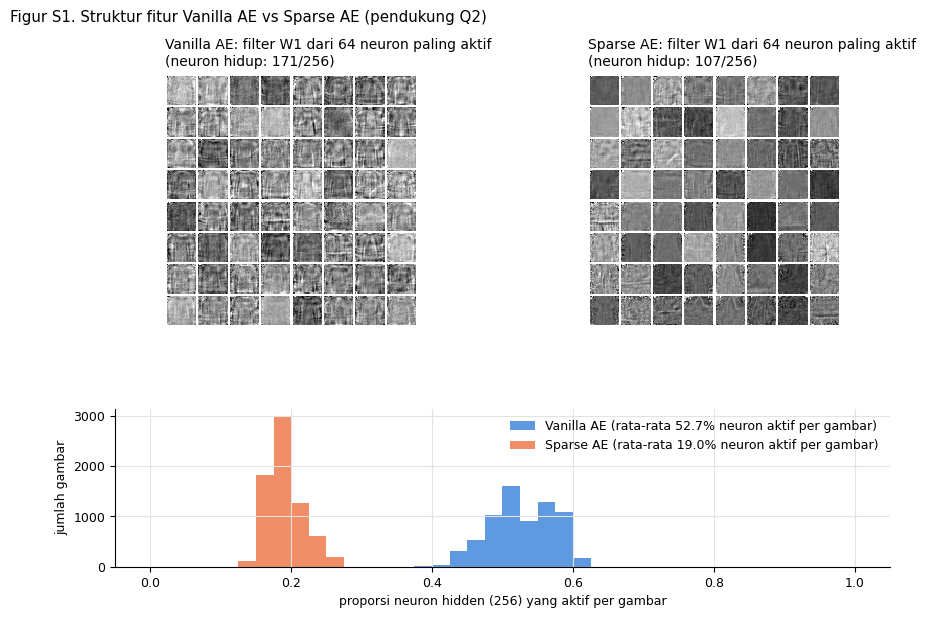

Figur tersimpan: c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results\figures\figureS2_gan_dynamics.png


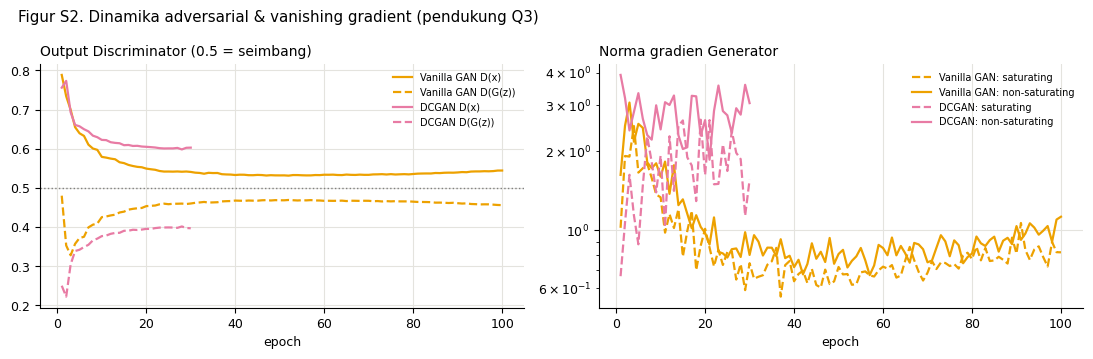

Figur tersimpan: c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results\figures\figureS3_interpolation_metrics.png


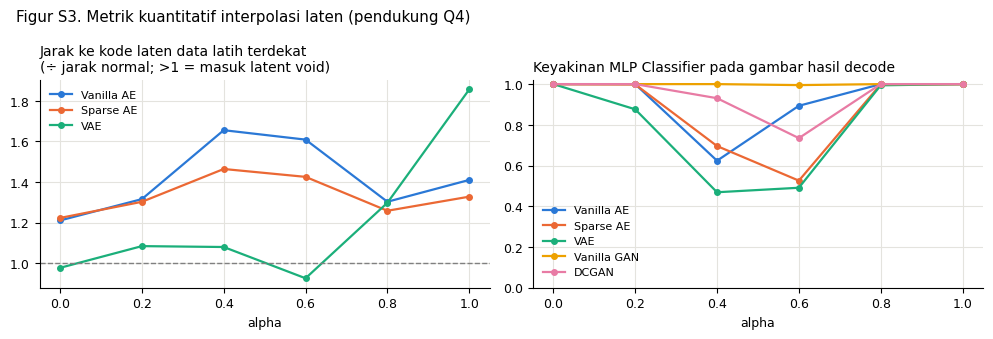

Figur tersimpan: c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results\figures\figureS4_mode_coverage.png


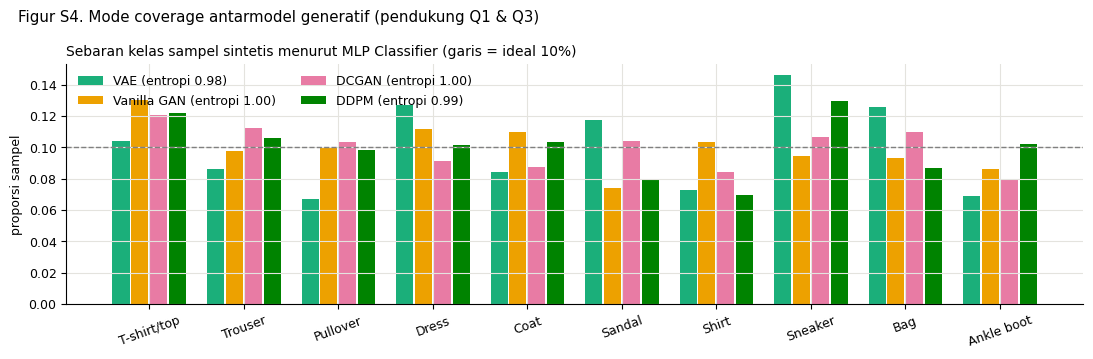

: 

In [ ]:
# ---- S1: filter W1 dari neuron yang PALING SERING AKTIF (neuron mati tidak ditampilkan)
ae_ck = {n: CKPT_DIR / f"{n}.pt" for n in ["vanilla_ae", "sparse_ae"]}
if all(p.exists() for p in ae_ck.values()):
    x_te = load_splits()["test"][0].flatten(1)
    fig = plt.figure(figsize=(10, 6.4))
    gs = GridSpec(2, 2, figure=fig, height_ratios=[1.6, 1], hspace=0.4)
    ax_h = fig.add_subplot(gs[1, :])
    for j, n in enumerate(["vanilla_ae", "sparse_ae"]):
        sd = torch.load(ae_ck[n], map_location="cpu")["model"]
        W1, b1 = sd["enc1.weight"], sd["enc1.bias"]                    # (256, 784), (256,)
        act = (F.relu(x_te @ W1.T + b1) > 1e-3).float()               # (n_test, 256)
        freq = act.mean(0)                                             # seberapa sering tiap neuron aktif
        alive = int((freq > 0).sum())
        top = freq.argsort(descending=True)[:min(64, max(alive, 1))]
        Wt = W1[top].view(-1, 1, 28, 28)
        Wt = (Wt - Wt.amin((1, 2, 3), keepdim=True)) / (Wt.amax((1, 2, 3), keepdim=True) - Wt.amin((1, 2, 3), keepdim=True) + 1e-8)
        show_imgs(fig.add_subplot(gs[0, j]), Wt, nrow=8,
                  title=f"{SHORT[n]}: filter W1 dari {len(top)} neuron paling aktif\n(neuron hidup: {alive}/256)")
        af = act.mean(1).numpy()
        ax_h.hist(af, bins=40, range=(0, 1), alpha=0.75, color=COLORS[n], label=f"{SHORT[n]} (rata-rata {af.mean():.1%} neuron aktif per gambar)")
    ax_h.set_xlabel("proporsi neuron hidden (256) yang aktif per gambar"); ax_h.set_ylabel("jumlah gambar"); ax_h.legend()
    fig.suptitle("Figur S1. Struktur fitur Vanilla AE vs Sparse AE (pendukung Q2)", x=0.02, ha="left")
    save_fig(fig, "figureS1_sparse_vs_vanilla_features"); plt.show()

# ---- S2
gans = [n for n in ["gan", "dcgan"] if n in H]
if gans:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    for n in gans:
        ep = H[n]["epoch"]
        axes[0].plot(ep, [e["D_x"] for e in H[n]["train"]], "-", color=COLORS[n], label=f"{SHORT[n]} D(x)")
        axes[0].plot(ep, [e["D_G_z"] for e in H[n]["train"]], "--", color=COLORS[n], label=f"{SHORT[n]} D(G(z))")
        axes[1].plot(ep, [d["saturating"] for d in H[n]["grad_diag"]], "--", color=COLORS[n], label=f"{SHORT[n]}: saturating")
        axes[1].plot(ep, [d["non_saturating"] for d in H[n]["grad_diag"]], "-", color=COLORS[n], label=f"{SHORT[n]}: non-saturating")
    axes[0].axhline(0.5, color="gray", ls=":", lw=1); axes[0].set_title("Output Discriminator (0.5 = seimbang)", loc="left")
    axes[1].set_yscale("log"); axes[1].set_title("Norma gradien Generator", loc="left")
    for ax in axes:
        ax.set_xlabel("epoch"); ax.legend(fontsize=7)
    fig.suptitle("Figur S2. Dinamika adversarial & vanishing gradient (pendukung Q3)", x=0.02, ha="left")
    fig.tight_layout(); save_fig(fig, "figureS2_gan_dynamics"); plt.show()

# ---- S3
if order:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    for n in order:
        r = A[n]["interp_rows"]
        if r[0]["nn_dist_ratio"] is not None:
            axes[0].plot(ALPHAS, [x["nn_dist_ratio"] for x in r], "-o", ms=4, color=COLORS[n], label=SHORT[n])
        if r[0]["classifier_max_conf"] is not None:
            axes[1].plot(ALPHAS, [x["classifier_max_conf"] for x in r], "-o", ms=4, color=COLORS[n], label=SHORT[n])
    axes[0].axhline(1.0, color="gray", ls="--", lw=1)
    axes[0].set_title("Jarak ke kode laten data latih terdekat\n(÷ jarak normal; >1 = masuk latent void)", loc="left")
    axes[1].set_title("Keyakinan MLP Classifier pada gambar hasil decode", loc="left"); axes[1].set_ylim(0, 1.02)
    for ax in axes:
        ax.set_xlabel("alpha"); ax.legend(fontsize=8)
    fig.suptitle("Figur S3. Metrik kuantitatif interpolasi laten (pendukung Q4)", x=0.02, ha="left")
    fig.tight_layout(); save_fig(fig, "figureS3_interpolation_metrics"); plt.show()

# ---- S4
gens = [n for n in ["vae", "gan", "dcgan", "ddpm"] if M.get(n, {}).get("mode_coverage")]
if gens:
    fig, ax = plt.subplots(figsize=(11, 3.6))
    w = 0.8 / len(gens)
    for i, n in enumerate(gens):
        mc = M[n]["mode_coverage"]
        ax.bar(np.arange(10) + i * w - 0.4 + w / 2, mc["class_hist"], width=w * 0.9, color=COLORS[n],
               label=f"{SHORT[n]} (entropi {mc['entropy_norm']:.2f})")
    ax.axhline(0.1, color="gray", ls="--", lw=1)
    ax.set_xticks(range(10)); ax.set_xticklabels(CLASS_NAMES, rotation=20)
    ax.set_ylabel("proporsi sampel"); ax.legend(ncol=2)
    ax.set_title("Sebaran kelas sampel sintetis menurut MLP Classifier (garis = ideal 10%)", loc="left")
    fig.suptitle("Figur S4. Mode coverage antarmodel generatif (pendukung Q1 & Q3)", x=0.02, ha="left")
    fig.tight_layout(); save_fig(fig, "figureS4_mode_coverage"); plt.show()

## 10. Selesai ✔

Semua bahan laporan ada di folder `results/`:
- `tables/metrics_table.md` / `.csv` → Bagian IV
- `tables/config_table.md` → Bagian II
- `tables/supporting_metrics.md`, `tables/interpolation_metrics.csv`, `metrics/*.json` → bahan analisis Q1–Q6
- `figures/` → Figur 1–5 (Bagian V) + Figur S1–S4